# Colorful Fashion Recommendation
**Deep Learning project**: detect fashion items with **YOLO**, extract features with **MobileNetV2**, and recommend similar items using **cosine similarity**.

**Workflow**
1. Load dataset and models
2. Detect and crop fashion items in a query image
3. Build a gallery of cropped items from the whole dataset
4. Extract features and compute similarity
5. Display the Top 5 recommendations for each detected item

## 1. Setup

In [1]:
# Import Libraries
import os
import pickle
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics.pairwise import cosine_similarity
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import img_to_array
from ultralytics import YOLO

C:\Anaconda3\envs\aidl\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


## 2. Load Dataset

In [2]:
# Load Dataset
DATASET_DIR=os.path.join(os.getcwd(),"dataset")
IMAGE_DIR=os.path.join(DATASET_DIR,"JPEGImages")
image_extensions=(".jpg",".jpeg",".png",".bmp")
image_paths=[]
for root,dirs,files in os.walk(IMAGE_DIR):
    for file in files:
        if file.lower().endswith(image_extensions):
            image_paths.append(os.path.join(root,file))

image_paths.sort()
print(f"Total fashion images: {len(image_paths)}")

Total fashion images: 2682


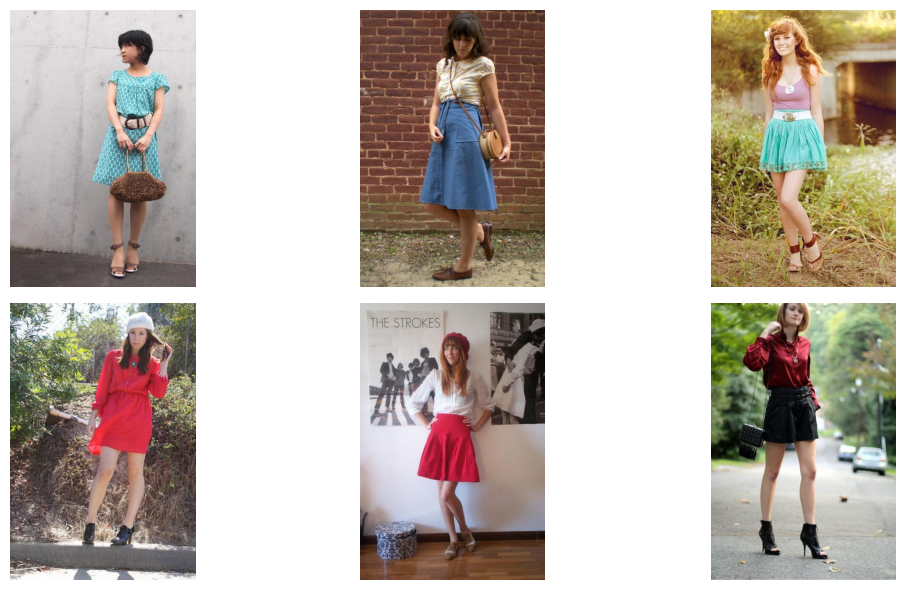

In [3]:
# Preview Fashion Images
plt.figure(figsize=(12,6))
for i in range(min(6,len(image_paths))):
    img=Image.open(image_paths[i]).convert("RGB")
    plt.subplot(2,3,i+1)
    plt.imshow(img)
    plt.axis("off")

plt.tight_layout()
plt.show()

## 3. Load Models (MobileNetV2 for features, YOLO for detection)

In [4]:
# Load Pretrained Model
feature_model=MobileNetV2(weights="imagenet",include_top=False,pooling="avg",input_shape=(224,224,3))

In [5]:
# Load Trained YOLO Model for Fashion Item Detection
yolo_model=YOLO(os.path.join("runs","detect","fashion_yolo_fast-2","weights","best.pt"))
print("YOLO model loaded successfully.")
print("YOLO Fashion Categories:", yolo_model.names)

YOLO model loaded successfully.
YOLO Fashion Categories: {0: 'sunglass', 1: 'hat', 2: 'jacket', 3: 'shirt', 4: 'pants', 5: 'shorts', 6: 'skirt', 7: 'dress', 8: 'bag', 9: 'shoe'}


## 4. Query Image: Detect and Crop Fashion Items

In [6]:
# Detect Fashion Items in the Input (Query) Image
query_index=0
query_image_path=image_paths[query_index]
results=yolo_model.predict(source=query_image_path,save=False,verbose=False)
print("Fashion item detection completed.")
for box in results[0].boxes:
    print(f"  Detected: {results[0].names[int(box.cls[0])]} (confidence {float(box.conf[0]):.2f})")

Fashion item detection completed.
  Detected: dress (confidence 0.94)
  Detected: bag (confidence 0.83)
  Detected: shoe (confidence 0.62)


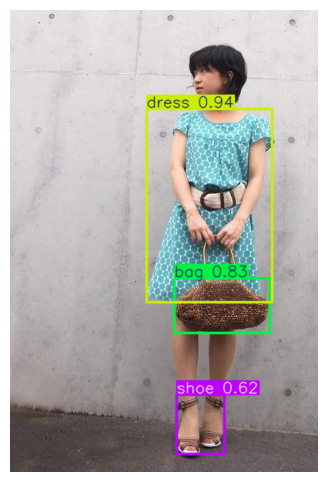

In [7]:
# Display YOLO Detection Output
detected_image=results[0].plot()
plt.figure(figsize=(8,6))
plt.imshow(cv2.cvtColor(detected_image,cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

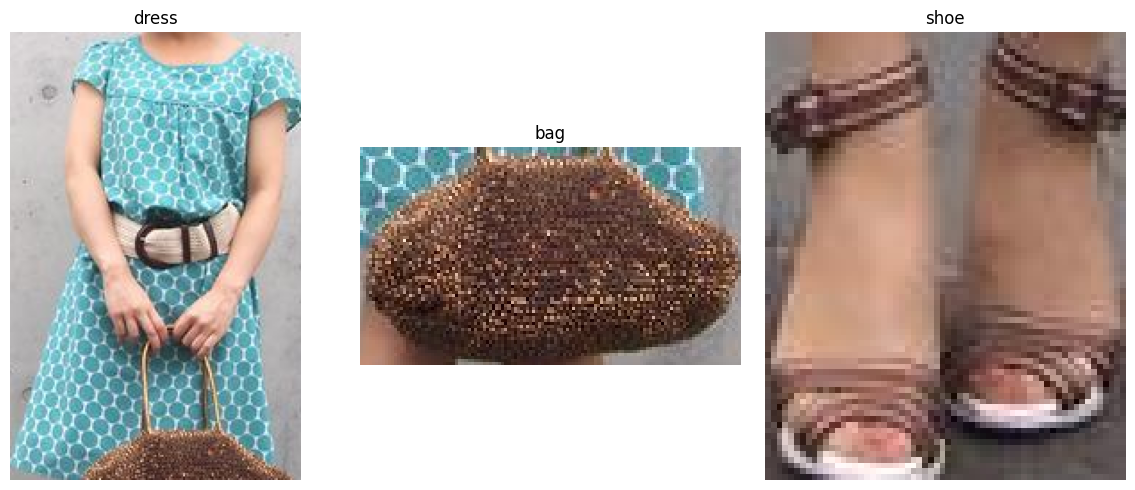

Total fashion items cropped: 3


In [8]:
# Crop and Display Detected Fashion Items
original_image=Image.open(query_image_path).convert("RGB")
boxes=results[0].boxes
cropped_items=[]

if boxes is not None and len(boxes)>0:
    plt.figure(figsize=(12,5))

    for i,box in enumerate(boxes):
        x1,y1,x2,y2=map(int,box.xyxy[0].tolist())
        cropped_image=original_image.crop((x1,y1,x2,y2))
        cropped_items.append({"image":cropped_image,
                              "label":results[0].names[int(box.cls[0])]})

        plt.subplot(1,len(boxes),i+1)
        plt.imshow(cropped_image)
        plt.title(cropped_items[i]["label"])
        plt.axis("off")

    plt.tight_layout()
    plt.show()
    print(f"Total fashion items cropped: {len(cropped_items)}")
else:
    print("No fashion items detected.")

In [9]:
# Extract Features from Cropped Fashion Items
cropped_features=[]
for item in cropped_items:
    img=item["image"].resize((224,224))
    img_array=img_to_array(img)
    img_array=preprocess_input(img_array)
    img_array=np.expand_dims(img_array,axis=0)
    item_features=feature_model.predict(img_array,verbose=0)
    cropped_features.append(item_features[0])

cropped_features=np.array(cropped_features)

print("Feature extraction completed for all detected items.")
print("Cropped feature shape:",cropped_features.shape)

Feature extraction completed for all detected items.
Cropped feature shape: (3, 1280)


## 5. Build the Dataset Crop Gallery (YOLO runs once per image)
Each detected dress / bag / shoe is stored as: source photo + box position + confidence.
The result is cached in `fashion_crop_cache.pkl`, so the next run loads in seconds.
(If you change the dataset or the YOLO model, delete that file once.)

In [10]:
# Build Category-Wise Crop Gallery from Dataset Images
CACHE_FILE="fashion_crop_cache.pkl"
target_categories=["dress","bag","shoe"]

def load_crop(m):
    # Re-create a crop (RGB) from its source photo and box position
    image=cv2.imread(m["source"])
    x1,y1,x2,y2=m["box"]
    return cv2.cvtColor(image[y1:y2,x1:x2],cv2.COLOR_BGR2RGB)

cache=None
if os.path.exists(CACHE_FILE):
    with open(CACHE_FILE,"rb") as f:
        cache=pickle.load(f)
    if cache.get("n_images")!=len(image_paths):
        cache=None   # dataset changed, rebuild

if cache is not None:
    category_meta=cache["meta"]
    print("Crop gallery loaded from cache.")
else:
    category_meta={c:[] for c in target_categories}
    for path in image_paths:
        image=cv2.imread(path)
        if image is None:
            continue
        h,w=image.shape[:2]
        detection=yolo_model(image,verbose=False)[0]

        for box in detection.boxes:
            category=yolo_model.names[int(box.cls[0])]
            if category not in category_meta:
                continue
            x1,y1,x2,y2=map(int,box.xyxy[0].tolist())
            x1,y1,x2,y2=max(0,x1),max(0,y1),min(w,x2),min(h,y2)
            if x2>x1 and y2>y1:
                category_meta[category].append({"source":path,"box":(x1,y1,x2,y2),"conf":float(box.conf[0])})
    print("Category-wise crops extracted.")

for category,metas in category_meta.items():
    print(f"{category.title()}: {len(metas)} crops")

Crop gallery loaded from cache.
Dress: 776 crops
Bag: 1713 crops
Shoe: 2852 crops


## 6. Extract Features from the Dataset Crops
Two kinds of features are used:
- **Shape / texture**: MobileNetV2 (deep learning features)
- **Colour**: HSV colour histogram of the centre of the crop (so recommendations follow the *colour* of the outfit too)

In [11]:
# Extract Shape (MobileNetV2) and Colour (HSV histogram) Features
def colour_feature(rgb):
    # HSV histogram of the central part of the crop (ignores most of the background)
    h,w=rgb.shape[:2]
    cy,cx=int(h*0.2),int(w*0.2)
    centre=rgb[cy:h-cy,cx:w-cx]
    if centre.size==0:
        centre=rgb
    hsv=cv2.cvtColor(centre,cv2.COLOR_RGB2HSV)
    hist=cv2.calcHist([hsv],[0,1],None,[18,8],[0,180,0,256]).flatten()
    hist=hist/(hist.sum()+1e-8)
    return np.sqrt(hist)   # cosine of these = colour similarity (0 to 1)

if cache is not None:
    category_crop_features=cache["cnn"]
    category_colour_features=cache["colour"]
    print("Features loaded from cache.")
else:
    category_crop_features={}
    category_colour_features={}
    batch_size=32
    for category,metas in category_meta.items():
        cnn_list=[]
        colour_list=[]
        for start in range(0,len(metas),batch_size):
            crops=[load_crop(m) for m in metas[start:start+batch_size]]
            batch=np.array([preprocess_input(img_to_array(Image.fromarray(c).resize((224,224))))
                            for c in crops])
            cnn_list.append(feature_model.predict(batch,verbose=0))
            colour_list.extend(colour_feature(c) for c in crops)
        if cnn_list:
            category_crop_features[category]=np.vstack(cnn_list)
            category_colour_features[category]=np.array(colour_list)
        print(f"{category.title()}: {len(metas)} crop features extracted.")

    with open(CACHE_FILE,"wb") as f:
        pickle.dump({"n_images":len(image_paths),"meta":category_meta,
                     "cnn":category_crop_features,"colour":category_colour_features},f)
    print("Features saved to cache.")

print("Category-wise feature extraction completed.")

Features loaded from cache.
Category-wise feature extraction completed.


## 7. Similarity and Top 5 Recommendations
Final score = `ALPHA` x shape/texture similarity + (1 - `ALPHA`) x colour similarity.
Set `ALPHA=1.0` to use only MobileNetV2 (shape/texture), or lower it to give colour more importance.

In [12]:
# Calculate Similarity and Select Top 5 Recommendations
ALPHA=0.7
TOP_K=5
recommendations=[]

for i,item in enumerate(cropped_items):
    category=item["label"]
    if category not in category_crop_features:
        continue

    shape_scores=cosine_similarity(cropped_features[i].reshape(1,-1),category_crop_features[category])[0]
    query_colour=colour_feature(np.array(item["image"])).reshape(1,-1)
    colour_scores=cosine_similarity(query_colour,category_colour_features[category])[0]
    scores=ALPHA*shape_scores+(1-ALPHA)*colour_scores
    meta=category_meta[category]

    # Never recommend crops from the query photo itself
    for j,m in enumerate(meta):
        if m["source"]==query_image_path:
            scores[j]=-1

    # Pick the best crops, at most one per source photo (no repeated photos)
    selected=[]
    used_sources=set()
    for idx in np.argsort(scores)[::-1]:
        if scores[idx]<0:
            break
        source=meta[idx]["source"]
        if source in used_sources:
            continue
        used_sources.add(source)
        selected.append({"idx":int(idx),"score":float(scores[idx]),
                         "shape":float(shape_scores[idx]),"colour":float(colour_scores[idx])})
        if len(selected)==TOP_K:
            break

    recommendations.append({"label":category,"query_crop":item["image"],"results":selected})
    print(f"{category.title()}: {len(selected)} recommendations prepared.")

Dress: 5 recommendations prepared.
Bag: 5 recommendations prepared.
Shoe: 5 recommendations prepared.


## 8. Final Recommendations


Dress - Top 5 Recommendations


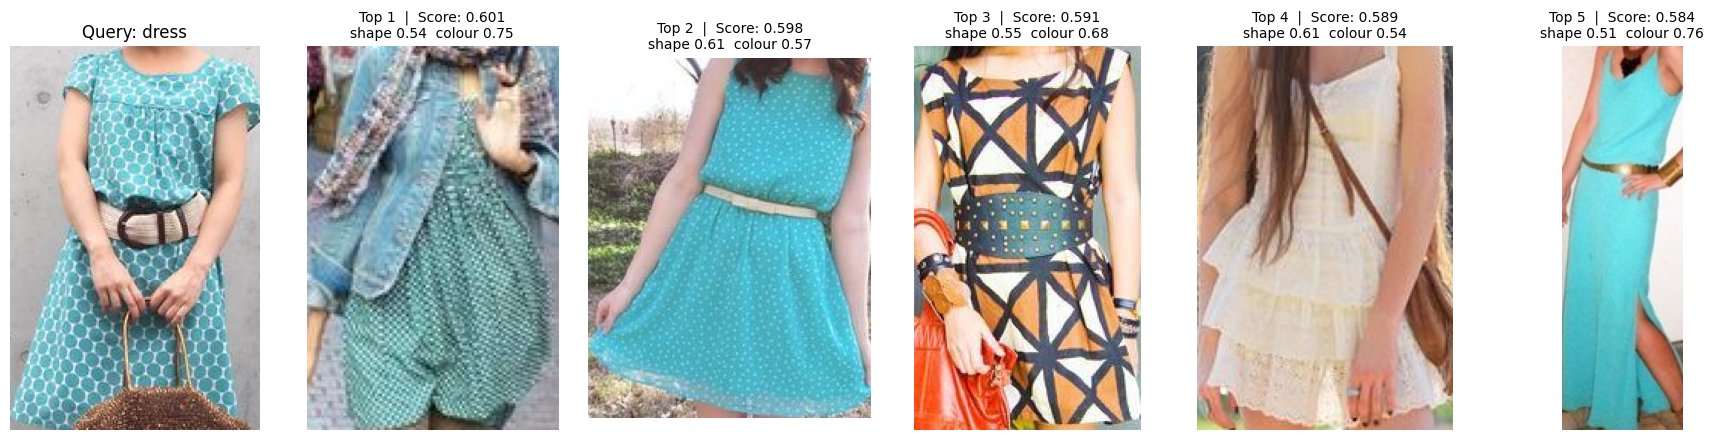


Bag - Top 5 Recommendations


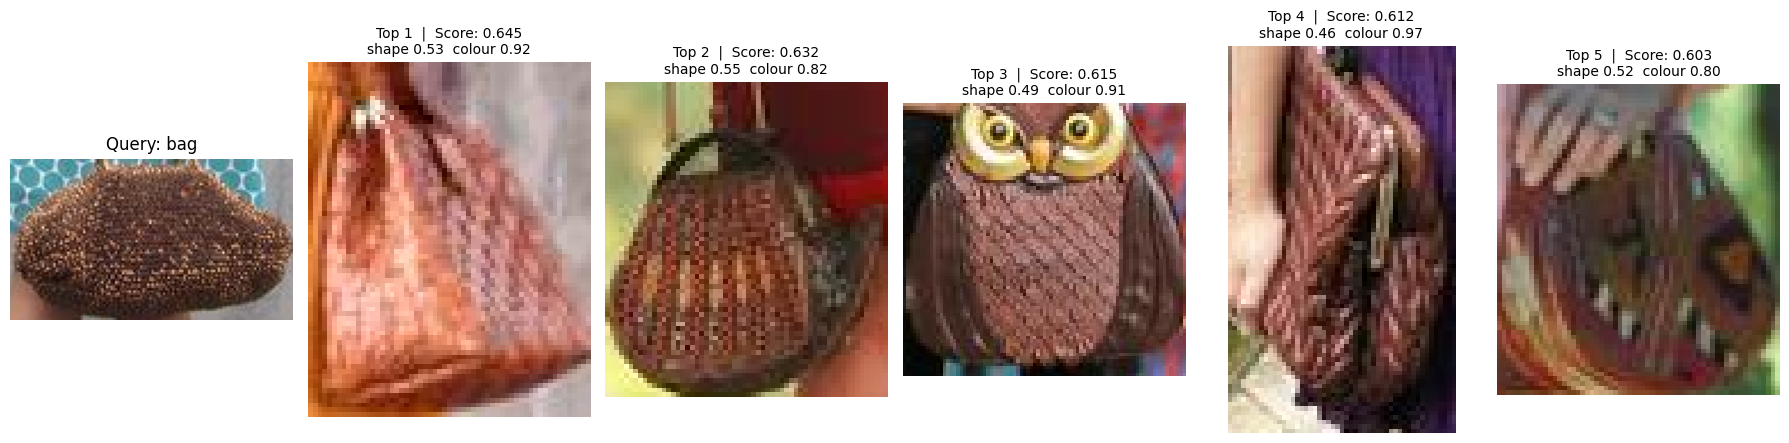


Shoe - Top 5 Recommendations


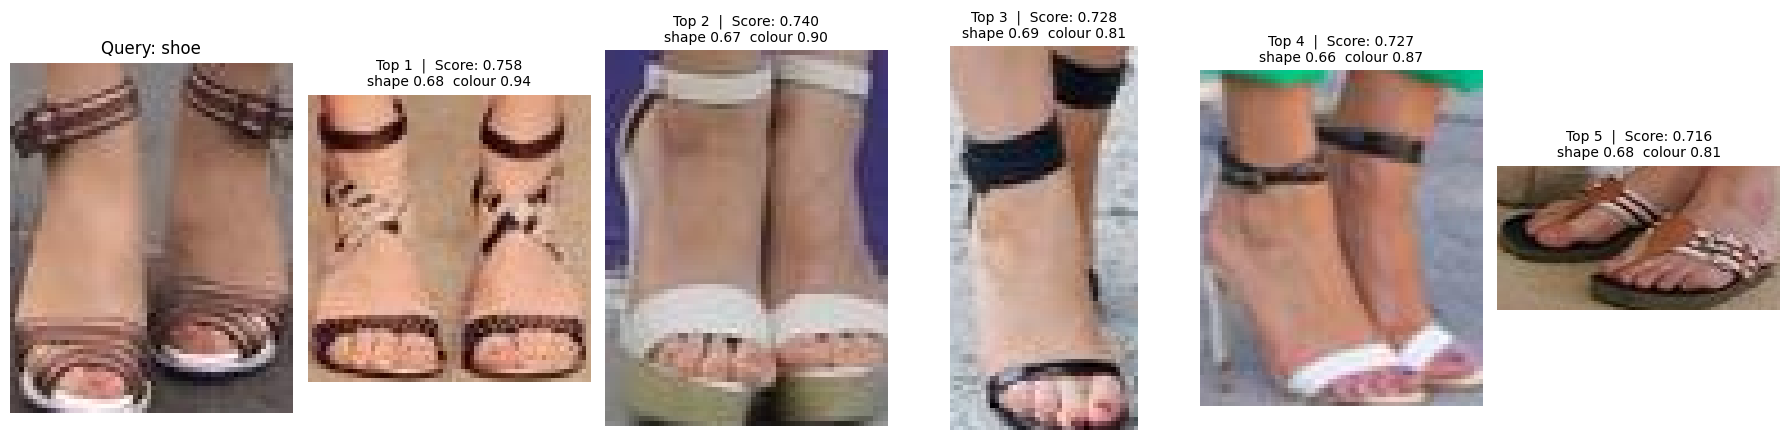

In [13]:
# Display Final Top 5 Fashion Recommendations
for rec in recommendations:
    category=rec["label"]
    n=len(rec["results"])
    print(f"\n{category.title()} - Top {n} Recommendations")
    plt.figure(figsize=(18,4.5))

    plt.subplot(1,n+1,1)
    plt.imshow(rec["query_crop"])
    plt.title(f"Query: {category}")
    plt.axis("off")

    for rank,r in enumerate(rec["results"],start=1):
        plt.subplot(1,n+1,rank+1)
        plt.imshow(load_crop(category_meta[category][r["idx"]]))
        plt.title(f"Top {rank}  |  Score: {r['score']:.3f}\nshape {r['shape']:.2f}  colour {r['colour']:.2f}",fontsize=10)
        plt.axis("off")

    plt.tight_layout()
    plt.show()